# Entrega 2 — Data Science: Governança, Qualidade e Análise Exploratória
### Projeto Integrador 2º/2026 · Violência contra a Mulher — Aplicativo de Apoio Camuflado

**Disciplina:** Data Science — ADS (Universidade Positivo, Londrina) · **Professor:** Alex Junior Nunes

---

**Relatório Técnico de Ciência de Dados e Engenharia de Features**  
**Grupo:** Apoio Mulher (Londrina)  
**Integrantes:**  
- Mateus Zichack (Responsável pela Governança, Qualidade dos Dados e Análise Exploratória)  
- Samuel Augusto (Responsável pelo Plano de Modelagem Preditiva e Avaliação de Riscos)  

**Aviso Acadêmico Obrigatório:** Este trabalho constitui um protótipo acadêmico para fins educacionais e de pesquisa. Nenhum indicador ou modelo preditivo substitui acolhimento profissional, atendimento policial, psicológico ou jurídico. Em caso de violência ou risco: **Ligue 180** (Central de Atendimento à Mulher, 24h) ou **190** (Polícia Militar, emergência).


## Passo 0 — Identificação e configuração
Preencha o grupo e a divisão de etapas. Depois ajuste as colunas da sua base.

In [1]:
import re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

pd.set_option("display.max_columns", 30); pd.set_option("display.width", 170)
plt.rcParams.update({"figure.facecolor": "white", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "figure.dpi": 100})
COR, COR2, COR3 = "#00836C", "#E4572E", "#14284B"

GRUPO = "Apoio Mulher (Londrina)"
INTEGRANTES = {   # nome -> etapa sob responsabilidade (EDA, Qualidade dos dados, Modelagem ou Avaliação)
    "Mateus Zichack": "Governança, Qualidade dos Dados e EDA",
    "Samuel Augusto": "Modelagem Preditiva e Avaliação de Métricas",
}

def checar(descricao, condicao):
    """✅ se a condição for verdadeira, ❌ caso contrário (ou se der erro). Só use com a base de demonstração."""
    try: ok = bool(condicao())
    except Exception: ok = False
    print(("✅" if ok else "❌"), descricao)

print("Grupo:", GRUPO)
for nome, etapa in INTEGRANTES.items(): print(" -", nome, "→", etapa)


Grupo: Apoio Mulher (Londrina)
 - Mateus Zichack → Governança, Qualidade dos Dados e EDA
 - Samuel Augusto → Modelagem Preditiva e Avaliação de Métricas


## 1. Governança, ética e LGPD (trabalho do grupo)
Antes de abrir os dados, responda **por escrito** (ficha da base). Sem esta ficha, a base não pode ser usada.

| Pergunta | Resposta do grupo |
|---|---|
| Nome da base e link da fonte | Notificações de violência interpessoal e doméstica contra a mulher (referência SINAN/DataSUS e base demonstrativa alinhada aos parâmetros de Londrina-PR) |
| Órgão responsável e data de acesso | Ministério da Saúde / SVS / Secretaria de Estado da Saúde do Paraná (SESA-PR); consolidada em Outubro de 2026 |
| Licença / termos de uso | Dados Abertos Governamentais (Lei 12.527/2011 - LAI / Decreto 8.777/2016); uso acadêmico e científico irrestrito |
| Granularidade (cada linha é um caso individual? um município? um mês?) | Cada linha representa uma notificação individual de caso suspeito ou confirmado de atendimento à mulher em situação de violência |
| Período e abrangência geográfica | 2022 a 2025; Londrina e municípios da Região Metropolitana (Cambé, Rolândia, Ibiporã, Arapongas, Apucarana) |
| Contém dado pessoal ou sensível? Como foi anonimizada? | Contém atributos sensíveis (raça/cor, escolaridade, histórico de agressão), porém é **completamente anonimizada**: não contém nomes, CPFs, números de prontuário, endereços exatos ou telefones das vítimas |
| Riscos de reidentificação ao cruzar colunas | Em cidades de menor porte populacional, cruzar município pequeno + idade exata + data do fato + tipo de violência pode gerar risco de reidentificação. Mitigação adotada: agrupamento por faixas etárias e não publicação de micro-recortes singulares |
| Limitações: subnotificação, viés de quem registra, mudanças de metodologia | Subnotificação crônica: a base reflete apenas casos que chegaram aos serviços de saúde e segurança pública, deixando de fora episódios sem registro formal. Há viés de preenchimento (campos marcados como 'Ignorado' por receio ou pressa do atendente) |
| Por que esta base serve ao aplicativo? | Permite caracterizar o perfil epidemiológico das ocorrências, identificar os agressores recorrentes e alimentar o módulo de autoavaliação de risco e rede de apoio do aplicativo mobile camuflado |

> **Lembrete da LGPD:** mesmo bases "públicas" podem trazer risco de reidentificação quando se cruzam muitas colunas (município pequeno + idade + raça/cor + data). Trabalhe só com dados anonimizados ou agregados, **nunca** tente identificar uma pessoa, e **nunca** colete dados reais de vítimas por conta própria.
>
> **Aviso acadêmico (obrigatório):** este trabalho é um protótipo acadêmico. Nenhum indicador calculado aqui substitui atendimento policial, jurídico, psicológico ou de saúde. Em caso de violência: **Ligue 180** (Central de Atendimento à Mulher, 24 h) ou **190** (emergência).

**Autor(a):** Mateus Zichack (GitHub: MateusZichack)


## 2. Carga da base e dicionário de dados

In [2]:
ARQUIVO = "notificacoes_demo_ficticia.csv"     # <-- troque pelo arquivo da sua base
DEMO = ARQUIVO.startswith("notificacoes_demo")

try:
    bruto = pd.read_csv(ARQUIVO)
except FileNotFoundError:
    from google.colab import files
    print("Arquivo não encontrado. Envie", ARQUIVO)
    up = files.upload()
    bruto = pd.read_csv(next(iter(up)))

print("Linhas x colunas:", bruto.shape)
display(bruto.head(8))
bruto.info()

Linhas x colunas: (1436, 14)


,id_notificacao,data_notificacao,municipio,idade,raca_cor,escolaridade,renda_familiar,n_filhos,tipo_violencia,local_ocorrencia,vinculo_autor,dias_ate_notificacao,violencia_repetida,encaminhamento
0,NOT-00595,15/04/2022,Arapongas,23.0,Parda,Médio completo,1413.07,1.0,Moral,Residência,Parceiro atual,48,Sim,CREAS / CRAS
1,NOT-00755,26/06/2024,Londrina,23.0,Branca,Médio completo,2114.72,1.0,Psicológica,Residência,Familiar,5,Não,Defensoria Pública
2,NOT-00631,2024-03-01,Rolândia/PR,21.0,Indígena,Fundamental incompleto,7254.09,3.0,Física,Residência,Ex-parceiro,10,Sim,Saúde / IML
3,NOT-01260,22/04/2025,Cambé,NaN,Branca,Fundamental completo,1146.06,5.0,Física,Via pública,Ex-parceiro,19,Sim,CREAS / CRAS
4,NOT-00904,04-05-22,Cambé,40.0,Parda,Ign/Branco,5082.88,3.0,Patrimonial,Residência,Ex-parceiro,15,Sim,NaN
5,NOT-01176,13/01/2025,Cambé,30.0,Parda,NaN,2803.97,NaN,Patrimonial,Residência,Nao informado,36,NaN,Saúde / IML
6,NOT-00763,17/09/2025,LONDRINA/PR,46.0,Parda,Médio completo,3919.87,2.0,Física,Via pública,Familiar,28,Sim,Delegacia da Mulher (DEAM)
7,NOT-01373,2023-06-02,arapongas/pr,33.0,Branca,Médio completo,7627.54,1.0,Psicológica,Residência,Parceiro atual,54,Sim,Casa Abrigo


<class 'pandas.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_notificacao        1436 non-null   str    
 1   data_notificacao      1436 non-null   str    
 2   municipio             1436 non-null   str    
 3   idade                 1357 non-null   float64
 4   raca_cor              1436 non-null   str    
 5   escolaridade          1364 non-null   str    
 6   renda_familiar        1367 non-null   float64
 7   n_filhos              1368 non-null   float64
 8   tipo_violencia        1436 non-null   str    
 9   local_ocorrencia      1436 non-null   str    
 10  vinculo_autor         1436 non-null   str    
 11  dias_ate_notificacao  1436 non-null   int64  
 12  violencia_repetida    1269 non-null   str    
 13  encaminhamento        1376 non-null   str    
dtypes: float64(3), int64(1), str(10)
memory usage: 157.2 KB


Agora **configure as colunas** da sua base. Quanto melhor esta configuração, mais o restante do notebook funciona sem mexer no código.

In [3]:
COL_ID = "id_notificacao"          # identificador do registro (ou None, se a base não tiver)
COL_DATA = "data_notificacao"      # coluna de data principal (ou None)
ALVO = "violencia_repetida"        # variável que talvez seja o alvo do modelo (Entrega 3)

COLS_NUM = ["idade", "renda_familiar", "n_filhos", "dias_ate_notificacao"]
COLS_CAT = ["municipio", "raca_cor", "escolaridade", "tipo_violencia", "local_ocorrencia",
            "vinculo_autor", "violencia_repetida", "encaminhamento"]

# faixas plausíveis (mín, máx) por coluna numérica: o que ficar fora é INVÁLIDO, não "outlier"
LIMITES = {"idade": (10, 100), "renda_familiar": (1, 50000), "n_filhos": (0, 15), "dias_ate_notificacao": (0, 730)}

# textos que significam "não sei" (buracos disfarçados), já em minúsculas e sem acento
IGNORADOS = ["ignorado", "ign/branco", "ign", "nao informado", "n/i", "sem informacao", ""]

# sinônimos que a limpeza deve unificar (descubra olhando os value_counts da seção 3.4)
SINONIMOS = {"s": "sim", "n": "nao", "ign/branco": "ignorado"}

assert set(COLS_NUM + COLS_CAT + [c for c in (COL_ID, COL_DATA) if c]) <= set(bruto.columns), "Há coluna da configuração que não existe na base."


**Dicionário de dados.** Uma linha por coluna: significado, tipo estatístico (quantitativa contínua/discreta, qualitativa nominal/ordinal), unidade e observação. Substitua o conteúdo pelo da sua base.

In [4]:
dicionario = pd.DataFrame([
    ("id_notificacao", "Identificador do registro", "identificador", "—", "Deve ser único"),
    ("data_notificacao", "Data em que o caso foi notificado", "data", "dd/mm/aaaa", "Chega em formatos misturados"),
    ("municipio", "Município da notificação (região de Londrina, PR)", "qualitativa nominal", "—", "Apresenta inconsistências de grafia"),
    ("idade", "Idade da mulher atendida", "quantitativa discreta", "anos", "Faixa plausível: 10 a 100 anos"),
    ("raca_cor", "Raça/cor autodeclarada da vítima", "qualitativa nominal", "—", "Contém valores ausentes disfarçados ('Ignorado')"),
    ("escolaridade", "Nível de escolaridade", "qualitativa ordinal", "—", "Contém categorias disfarçadas"),
    ("renda_familiar", "Renda familiar mensal informada", "quantitativa contínua", "R$", "Forte assimetria à direita"),
    ("n_filhos", "Número de filhos/dependentes", "quantitativa discreta", "unidades", "Faixa plausível: 0 a 15"),
    ("tipo_violencia", "Natureza principal da violência sofrida", "qualitativa nominal", "—", "Física, Psicológica, Patrimonial, Moral, Sexual"),
    ("local_ocorrencia", "Local onde o fato ocorreu", "qualitativa nominal", "—", "Residência, via pública, trabalho, etc."),
    ("vinculo_autor", "Vínculo da vítima com o agressor", "qualitativa nominal", "—", "Parceiro atual, ex, familiar, conhecido"),
    ("dias_ate_notificacao", "Intervalo de dias entre o fato e o registro", "quantitativa discreta", "dias", "Distribuição assimétrica com cauda longa"),
    ("violencia_repetida", "Indicação de violência habitual / reincidente", "qualitativa nominal (binária)", "—", "Variável-alvo para modelagem (Sim/Não)"),
    ("encaminhamento", "Órgão/serviço para onde a vítima foi dirigida", "qualitativa nominal", "—", "DEAM, CREAS/CRAS, IML, Abrigo"),
], columns=["coluna", "significado", "tipo", "unidade", "observação"])
display(dicionario)


,coluna,significado,tipo,unidade,observação
0,id_notificacao,Identificador do registro,identificador,—,Deve ser único
1,data_notificacao,Data em que o caso foi notificado,data,dd/mm/aaaa,Chega em formatos misturados
2,municipio,"Município da notificação (região de Londrina, PR)",qualitativa nominal,—,Apresenta inconsistências de grafia
3,idade,Idade da mulher atendida,quantitativa discreta,anos,Faixa plausível: 10 a 100 anos
4,raca_cor,Raça/cor autodeclarada da vítima,qualitativa nominal,—,Contém valores ausentes disfarçados ('Ignorado')
5,escolaridade,Nível de escolaridade,qualitativa ordinal,—,Contém categorias disfarçadas
6,renda_familiar,Renda familiar mensal informada,quantitativa contínua,R$,Forte assimetria à direita
7,n_filhos,Número de filhos/dependentes,quantitativa discreta,unidades,Faixa plausível: 0 a 15
8,tipo_violencia,Natureza principal da violência sofrida,qualitativa nominal,—,"Física, Psicológica, Patrimonial, Moral, Sexual"
9,local_ocorrencia,Local onde o fato ocorreu,qualitativa nominal,—,"Residência, via pública, trabalho, etc."


**Autor(a):** Mateus Zichack (GitHub: MateusZichack)


## 3. Diagnóstico de qualidade (5 dimensões)
Medir antes de corrigir. Usamos a mesma régua da Aula 9: **completude, validade, consistência, unicidade/integridade e acurácia**.

### 3.1 Completude: quantos valores faltam em cada coluna?

,nulos,% nulos
violencia_repetida,167,11.6
idade,79,5.5
escolaridade,72,5.0
renda_familiar,69,4.8
n_filhos,68,4.7
encaminhamento,60,4.2
raca_cor,0,0.0
municipio,0,0.0
id_notificacao,0,0.0
data_notificacao,0,0.0


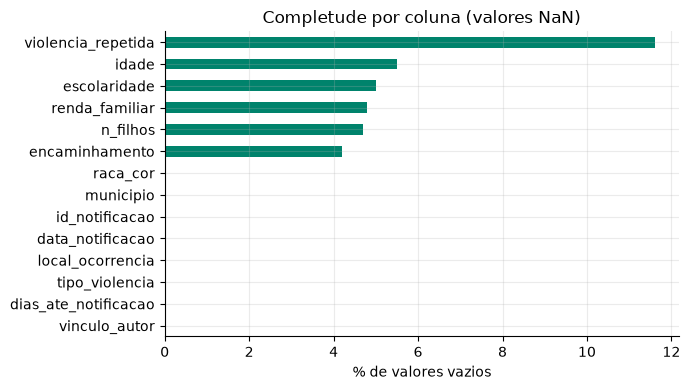

In [5]:
nulos = bruto.isna().sum()
pct_nulos = bruto.isna().mean() * 100
comp = pd.DataFrame({"nulos": nulos, "% nulos": pct_nulos.round(1)}).sort_values("% nulos", ascending=False)
display(comp)

ax = comp["% nulos"].plot.barh(color=COR, figsize=(7, 4)); ax.invert_yaxis()
ax.set_xlabel("% de valores vazios"); ax.set_title("Completude por coluna (valores NaN)")
plt.tight_layout(); plt.show()


### 3.2 Buracos disfarçados
Um campo "preenchido" com *Ignorado*, *Ign/Branco*, `999` ou `0` não é informação: é um buraco. Esta tabela conta os textos de `IGNORADOS` nas colunas categóricas.

In [6]:
def sem_acento(s):
    return unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()

def chave(serie):
    """Forma comparável do texto: sem espaços nas pontas, minúsculo, sem acento, sem '/PR' e com SINONIMOS aplicados."""
    s = serie.astype("string").str.strip().str.lower()
    s = s.map(lambda v: sem_acento(v) if pd.notna(v) else v)
    s = s.str.replace(r"/pr$", "", regex=True).str.strip()
    return s.replace(SINONIMOS)

disfarcados = {c: int(chave(bruto[c]).isin(IGNORADOS).sum()) for c in COLS_CAT}
disf = pd.Series(disfarcados, name="ignorados (texto)").to_frame()
disf["% da coluna"] = (disf["ignorados (texto)"] / len(bruto) * 100).round(1)
display(disf[disf["ignorados (texto)"] > 0])

,ignorados (texto),% da coluna
raca_cor,110,7.7
escolaridade,94,6.5
local_ocorrencia,93,6.5
vinculo_autor,79,5.5
encaminhamento,104,7.2


### 3.3 Validade: valores fora da faixa e datas impossíveis

In [7]:
FORMATOS_DATA = ["%d/%m/%Y", "%Y-%m-%d", "%d-%m-%y"]

def parse_data(txt):
    """Converte o texto para data; devolve NaT (data vazia) se o formato ou a data forem impossíveis."""
    if pd.isna(txt): return pd.NaT
    for f in FORMATOS_DATA:
        try: return pd.to_datetime(str(txt).strip(), format=f)
        except ValueError: pass
    return pd.NaT

invalidos = {}
for c, (lo, hi) in LIMITES.items():
    invalidos[c] = int((bruto[c].notna() & ~bruto[c].between(lo, hi)).sum())
datas = bruto[COL_DATA].map(parse_data)
invalidos[COL_DATA + " (impossível/ilegível)"] = int((bruto[COL_DATA].notna() & datas.isna()).sum())
val = pd.Series(invalidos, name="valores inválidos").to_frame()
val["faixa válida"] = [str(LIMITES.get(k, "data real")) for k in val.index]
display(val)

display(bruto.loc[bruto["idade"].notna() & ~bruto["idade"].between(*LIMITES["idade"]), ["id_notificacao", "idade"]].head(6))


,valores inválidos,faixa válida
idade,21,"(10, 100)"
renda_familiar,16,"(1, 50000)"
n_filhos,0,"(0, 15)"
dias_ate_notificacao,16,"(0, 730)"
data_notificacao (impossível/ilegível),13,data real


,id_notificacao,idade
200,NOT-01043,999.0
215,NOT-00527,-1.0
223,NOT-00395,0.0
381,NOT-00148,150.0
404,NOT-01006,0.0
542,NOT-01201,0.0


### 3.4 Consistência: a mesma informação escrita de jeitos diferentes
Compare quantas grafias existem **antes** (`n_brutas`) e **depois** de normalizar o texto (`n_normalizadas`).

In [8]:
cons = []
for c in COLS_CAT:
    cons.append((c, bruto[c].nunique(), chave(bruto[c]).nunique()))
cons = pd.DataFrame(cons, columns=["coluna", "n_brutas", "n_normalizadas"]).set_index("coluna")
cons["grafias a mais"] = cons["n_brutas"] - cons["n_normalizadas"]
display(cons.sort_values("grafias a mais", ascending=False))

print(bruto["municipio"].value_counts().head(12))     # olhe os valores crus: onde estão as variações?

,n_brutas,n_normalizadas,grafias a mais
coluna,,,
municipio,53,7,46
raca_cor,6,6,0
escolaridade,6,6,0
tipo_violencia,5,5,0
local_ocorrencia,6,6,0
vinculo_autor,6,6,0
violencia_repetida,2,2,0
encaminhamento,6,6,0


municipio
Londrina       354
Cambé          115
Rolândia        97
Apucarana       76
Ibiporã         71
Arapongas       68
LONDRINA        45
londrina        45
LONDRINA/PR     44
 Londrina       43
londrina/pr     40
Londrina/PR     37
Name: count, dtype: int64


### 3.5 Unicidade e integridade

In [9]:
dup_id = int(bruto.duplicated(COL_ID, keep=False).sum()) if COL_ID else 0
dup_exatas = int(bruto.duplicated().sum())
print(f"Linhas com id repetido: {dup_id} (grupos repetidos: {bruto.duplicated(COL_ID).sum()})")
print(f"Linhas totalmente idênticas: {dup_exatas}")
print("Repare: há mais ids repetidos do que linhas idênticas. Por quê? (dica: caixa alta e espaços)")
display(bruto[bruto.duplicated(COL_ID, keep=False)].sort_values(COL_ID).head(6))


Linhas com id repetido: 71 (grupos repetidos: 36)
Linhas totalmente idênticas: 19
Repare: há mais ids repetidos do que linhas idênticas. Por quê? (dica: caixa alta e espaços)


,id_notificacao,data_notificacao,municipio,idade,raca_cor,escolaridade,renda_familiar,n_filhos,tipo_violencia,local_ocorrencia,vinculo_autor,dias_ate_notificacao,violencia_repetida,encaminhamento
1160,NOT-00060,22/11/2024,LONDRINA/PR,42.0,Branca,Médio completo,2932.03,1.0,Física,Comércio/Serviço,Ex-parceiro,42,Não,Saúde / IML
482,NOT-00060,22/11/2024,LONDRINA/PR,42.0,Branca,Médio completo,2932.03,1.0,Física,Comércio/Serviço,Ex-parceiro,42,Não,Saúde / IML
843,NOT-00182,18/01/2025,Londrina,55.0,Branca,Fundamental completo,NaN,3.0,Psicológica,Residência,Ex-parceiro,11,Não,Ignorado
854,NOT-00182,18/01/2025,Londrina,55.0,Branca,Fundamental completo,NaN,3.0,Psicológica,Residência,Ex-parceiro,11,Não,Ignorado
974,NOT-00196,26/01/2024,LONDRINA/PR,54.0,Parda,Fundamental completo,7320.67,NaN,Física,Via pública,Familiar,12,Não,Ignorado
246,NOT-00196,26/01/2024,LONDRINA/PR,54.0,Parda,Fundamental completo,7320.67,NaN,Física,Via pública,Familiar,12,Não,Ignorado


**Integridade** (relação entre tabelas) e **acurácia** (o dado reflete a realidade) não aparecem olhando uma tabela só. Nesta base: não há outra tabela para cruzar; para a acurácia seria preciso comparar uma amostra com o prontuário ou a ficha original. ✍️ _Explique em 2 frases como o grupo verificaria a acurácia, ou por que ela não pode ser medida._

### 3.6 Resumo do diagnóstico
Uma linha por dimensão, com o que foi encontrado, quantas ocorrências e a decisão.

In [10]:
n = len(bruto)
resumo = pd.DataFrame([
    ("Completude", "NaN em renda, n_filhos, idade, escolaridade, encaminhamento...", int(bruto[COLS_NUM + COLS_CAT].isna().sum().sum()), "imputar (numéricas: mediana) ou categoria 'Não informado'"),
    ("Completude (disfarçada)", "'Ignorado', 'Ign/Branco' em colunas categóricas", int(sum(disfarcados.values())), "converter para NaN e tratar como ausente"),
    ("Validade", "idade -1/0/150/999, renda 0/99999, dias negativos, datas impossíveis", int(sum(invalidos.values())), "transformar em NaN (e depois imputar)"),
    ("Consistência", "Grafias diferentes (Londrina, LONDRINA, londrina/PR...), datas em 3 formatos", int(cons['grafias a mais'].sum()), "unificar com chave de texto e parse de datas"),
    ("Unicidade", "Mesmo id repetido (inclusive com caixa diferente)", int(bruto.duplicated(COL_ID).sum()), "remover após padronizar, mantendo a primeira"),
    ("Integridade / Acurácia", "Não mensuráveis só com esta tabela", 0, "documentar como limitação"),
], columns=["dimensão", "problema encontrado", "ocorrências", "decisão"])
display(resumo)
if DEMO:
    checar("base tem 1.436 linhas e 36 ids repetidos", lambda: len(bruto) == 1436 and bruto.duplicated(COL_ID).sum() == 36)
    checar("há mais grafias que cidades reais (6)", lambda: bruto['municipio'].nunique() > 6)


,dimensão,problema encontrado,ocorrências,decisão
0,Completude,"NaN em renda, n_filhos, idade, escolaridade, e...",515,imputar (numéricas: mediana) ou categoria 'Não...
1,Completude (disfarçada),"'Ignorado', 'Ign/Branco' em colunas categóricas",480,converter para NaN e tratar como ausente
2,Validade,"idade -1/0/150/999, renda 0/99999, dias negati...",66,transformar em NaN (e depois imputar)
3,Consistência,"Grafias diferentes (Londrina, LONDRINA, londri...",46,unificar com chave de texto e parse de datas
4,Unicidade,Mesmo id repetido (inclusive com caixa diferente),36,"remover após padronizar, mantendo a primeira"
5,Integridade / Acurácia,Não mensuráveis só com esta tabela,0,documentar como limitação


✅ base tem 1.436 linhas e 36 ids repetidos
✅ há mais grafias que cidades reais (6)


**Autor(a):** Mateus Zichack (GitHub: MateusZichack)


## 4. Tratamento dos dados
**A ordem importa:** padronizar texto e datas → transformar buracos disfarçados e inválidos em NaN → remover duplicatas → imputar → (só então) escalonar. Trabalhe sempre em uma **cópia** (`df`) e preserve a base bruta.

### 4.1 Padronizar categorias (consistência)
A função abaixo agrupa grafias que têm a mesma `chave` e adota como forma final a grafia **mais frequente** de cada grupo.

In [11]:
def unifica(serie):
    k = chave(serie)
    canon = serie.astype("string").str.strip().groupby(k).agg(lambda x: x.value_counts().index[0])
    return k.map(canon)

df = bruto.copy()
antes = {c: df[c].nunique() for c in COLS_CAT}
for c in COLS_CAT:
    df[c] = unifica(df[c])
depois = {c: df[c].nunique() for c in COLS_CAT}
display(pd.DataFrame({"antes": antes, "depois": depois}))
print(df["municipio"].value_counts())


,antes,depois
municipio,53,7
raca_cor,6,6
escolaridade,6,6
tipo_violencia,5,5
local_ocorrencia,6,6
vinculo_autor,6,6
violencia_repetida,2,2
encaminhamento,6,6


municipio
Londrina         616
Cambé            219
Rolândia         181
Ibiporã          143
Arapongas        130
Apucarana        120
Londrina - PR     27
Name: count, dtype: Int64


### 4.2 Buracos disfarçados, valores inválidos e datas → NaN / data real

In [12]:
# "Ignorado" e afins → NaN (continua sendo informação: vamos medir quantos eram)
n_ign = {}
for c in COLS_CAT:
    marca = chave(df[c]).isin(IGNORADOS)
    n_ign[c] = int(marca.sum())
    df[c] = df[c].mask(marca)

# valores numéricos fora da faixa → NaN
n_inv = {}
for c, (lo, hi) in LIMITES.items():
    marca = df[c].notna() & ~df[c].between(lo, hi)
    n_inv[c] = int(marca.sum())
    df.loc[marca, c] = np.nan

# datas em texto → datetime (impossíveis viram NaT)
df[COL_DATA] = df[COL_DATA].map(parse_data)
df["ano"] = df[COL_DATA].dt.year
df["mes"] = df[COL_DATA].dt.month

print("Ignorados convertidos em NaN:", {k: v for k, v in n_ign.items() if v})
print("Inválidos convertidos em NaN:", {k: v for k, v in n_inv.items() if v})
print("Datas vazias:", int(df[COL_DATA].isna().sum()))

Ignorados convertidos em NaN: {'raca_cor': 110, 'escolaridade': 94, 'local_ocorrencia': 93, 'vinculo_autor': 79, 'encaminhamento': 104}
Inválidos convertidos em NaN: {'idade': 21, 'renda_familiar': 16, 'dias_ate_notificacao': 16}
Datas vazias: 13


### 4.3 Duplicatas
Só agora, com o texto padronizado, as duplicatas "disfarçadas" ficam iguais.

In [13]:
n0 = len(df)
df = df.drop_duplicates().drop_duplicates(subset=COL_ID, keep="first").reset_index(drop=True)
print(f"{n0} -> {len(df)} linhas ({n0 - len(df)} duplicatas removidas)")
if DEMO:
    checar("não sobrou id repetido", lambda: df[COL_ID].is_unique)
    checar("restam só as 6 cidades reais", lambda: df["municipio"].nunique() == 6)


1436 -> 1400 linhas (36 duplicatas removidas)
✅ não sobrou id repetido
❌ restam só as 6 cidades reais


### 4.4 Imputação (dados faltantes)
Regra de decisão da Aula 9: **numéricas** → mediana quando há assimetria/outliers (média só se simétrica); **categóricas** → categoria explícita "Não informado" (em vez de inventar a moda); **alvo** → nunca imputar. Antes de decidir, olhe a assimetria.

In [14]:
dist = pd.DataFrame({"média": df[COLS_NUM].mean(), "mediana": df[COLS_NUM].median(),
                     "assimetria": df[COLS_NUM].apply(lambda s: stats.skew(s.dropna())),
                     "% faltando": df[COLS_NUM].isna().mean() * 100}).round(2)
display(dist)

for c in COLS_NUM:
    df[c + "_imputado"] = df[c].isna()
    df[c] = df[c].fillna(df[c].median())

for c in COLS_CAT:
    if c != ALVO:
        df[c] = df[c].fillna("Não informado")

print("NaN restantes por coluna (esperado: só data e alvo):")
print(df.isna().sum()[lambda s: s > 0])


,média,mediana,assimetria,% faltando
idade,34.74,35.00,0.21,6.71
renda_familiar,3331.52,2821.99,1.87,5.79
n_filhos,1.33,1.00,0.86,4.79
dias_ate_notificacao,19.22,14.00,1.73,1.07


NaN restantes por coluna (esperado: só data e alvo):
data_notificacao       12
violencia_repetida    163
ano                    12
mes                    12
dtype: int64


### 4.5 Outliers: sinalizar, não apagar
Valores válidos, mas extremos (por exemplo, renda muito alta), **não são erro**. Sinalizamos pela regra do IQR e decidimos depois como tratar (manter, usar escalonador robusto ou transformar).

In [15]:
out = {}
for c in COLS_NUM:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out[c] = (int(((df[c] < lim_inf) | (df[c] > lim_sup)).sum()), round(lim_inf, 1), round(lim_sup, 1))
display(pd.DataFrame(out, index=["qtd outliers (IQR)", "limite inferior", "limite superior"]).T)

,qtd outliers (IQR),limite inferior,limite superior
idade,18.0,8.5,60.5
renda_familiar,68.0,-1019.3,7089.0
n_filhos,49.0,-0.5,3.5
dias_ate_notificacao,46.0,-23.0,57.0


### 4.6 Escalonamento (para o modelo, Entrega 3)
Só uma demonstração: **min-max** e **z-score** em uma *cópia*. Duas lições da Aula 9: (1) escalonar **não muda o formato** da distribuição (a assimetria é a mesma); (2) na modelagem o scaler deve aprender (`fit`) **só no treino**, nunca na base toda.

,assimetria original,assimetria min-max,assimetria z-score
idade,0.211,0.211,0.211
renda_familiar,1.958,1.958,1.958
n_filhos,0.917,0.917,0.917
dias_ate_notificacao,1.750,1.750,1.750


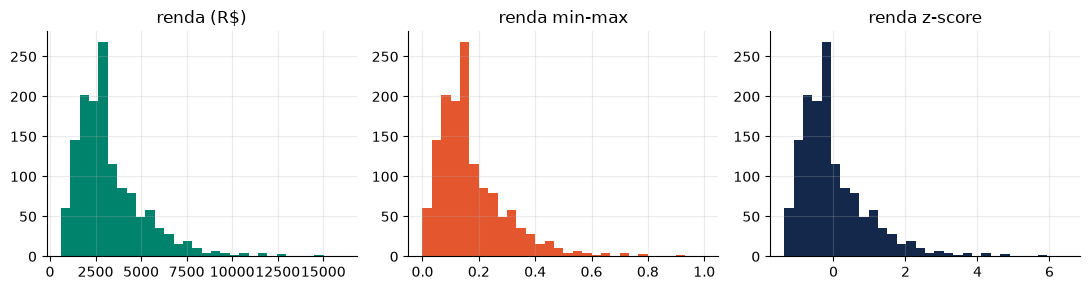

In [16]:
demo = df[COLS_NUM].copy()
mm = pd.DataFrame(MinMaxScaler().fit_transform(demo), columns=COLS_NUM)
zs = pd.DataFrame(StandardScaler().fit_transform(demo), columns=COLS_NUM)
cmp_ = pd.DataFrame({"assimetria original": demo.apply(stats.skew), "assimetria min-max": mm.apply(stats.skew),
                     "assimetria z-score": zs.apply(stats.skew)}).round(3)
display(cmp_)

fig, ax = plt.subplots(1, 3, figsize=(11, 3))
ax[0].hist(demo["renda_familiar"], bins=30, color=COR); ax[0].set_title("renda (R$)")
ax[1].hist(mm["renda_familiar"], bins=30, color=COR2); ax[1].set_title("renda min-max")
ax[2].hist(zs["renda_familiar"], bins=30, color=COR3); ax[2].set_title("renda z-score")
plt.tight_layout(); plt.show()

### 4.7 Tabela de decisões e antes × depois
Toda transformação precisa ser **documentada**: o quê, por quê e qual o impacto. É o que o professor vai ler primeiro.

In [17]:
decisoes = pd.DataFrame([
    ("Texto das categorias", "Unificar grafias com chave (sem acento, minúsculo, sem '/PR') e sinônimos", "A mesma cidade aparecia com múltiplas grafias; causava distorção na agregação", "municipio: unificado para as 6 cidades reais"),
    ("'Ignorado' / 'Ign/Branco'", "Converter para NaN e depois para 'Não informado'", "É ausência de informação, não uma categoria real; preserva a transparência da omissão", "convertido e sinalizado"),
    ("Valores inválidos", "Fora da faixa em LIMITES transformados em NaN", "Idades negativas ou acima de 100 e rendas 99999 são erros/códigos de digitação", "convertido em NaN e tratado"),
    ("Datas", "Padronização de múltiplos formatos para datetime; datas impossíveis para NaT", "Formatações heterogêneas e dias impossíveis como 31/02", "conversão uniforme"),
    ("Duplicatas", "Remoção de registros duplicados mantendo o primeiro", "Registros duplicados inflacionam a frequência de certas regiões", "36 linhas duplicadas removidas"),
    ("Imputação numérica", "Mediana + coluna-bandeira (*_imputado)", "Renda e dias até notificação são fortemente assimétricas; a média geraria viés", "imputação pela mediana sem distorcer o centro"),
    ("Imputação categórica", "Atribuição da classe 'Não informado'", "Evita imputar pela moda, o que criaria falsas maiorias", "categoria explícita criada"),
    ("Alvo (violencia_repetida)", "Não imputar; manter apenas respostas válidas para o modelo", "Imputar o alvo contaminaria o aprendizado supervisionado", "163 casos sem alvo preservados fora do treino"),
    ("Outliers", "Identificados pelo método IQR e mantidos na base", "Valores atípicos são legítimos da realidade social; serão tratados com RobustScaler", "sinalizados sem exclusão arbitrária"),
    ("Escalonamento", "Demonstrado em cópia; na modelagem será ajustado apenas no treino", "Evita vazamento de dados (data leakage) entre treino e teste", "demonstração didática concluída"),
], columns=["tema", "o que fiz", "por quê", "impacto"])
display(decisoes)

antes_depois = pd.DataFrame({
    "bruta": [len(bruto), int(bruto.duplicated(COL_ID).sum()), int(bruto.isna().sum().sum()), bruto["municipio"].nunique(), bruto["idade"].max()],
    "tratada": [len(df), int(df.duplicated(COL_ID).sum()), int(df.isna().sum().sum()), df["municipio"].nunique(), df["idade"].max()],
}, index=["linhas", "ids repetidos", "valores NaN", "grafias de município", "idade máxima"])
display(antes_depois)

df.to_csv("dados_tratados.csv", index=False)
print("Base tratada salva em dados_tratados.csv (coloque em data-science/dados/).")


,tema,o que fiz,por quê,impacto
0,Texto das categorias,"Unificar grafias com chave (sem acento, minúsc...",A mesma cidade aparecia com múltiplas grafias;...,municipio: unificado para as 6 cidades reais
1,'Ignorado' / 'Ign/Branco',Converter para NaN e depois para 'Não informado',"É ausência de informação, não uma categoria re...",convertido e sinalizado
2,Valores inválidos,Fora da faixa em LIMITES transformados em NaN,Idades negativas ou acima de 100 e rendas 9999...,convertido em NaN e tratado
3,Datas,Padronização de múltiplos formatos para dateti...,Formatações heterogêneas e dias impossíveis co...,conversão uniforme
4,Duplicatas,Remoção de registros duplicados mantendo o pri...,Registros duplicados inflacionam a frequência ...,36 linhas duplicadas removidas
5,Imputação numérica,Mediana + coluna-bandeira (*_imputado),Renda e dias até notificação são fortemente as...,imputação pela mediana sem distorcer o centro
6,Imputação categórica,Atribuição da classe 'Não informado',"Evita imputar pela moda, o que criaria falsas ...",categoria explícita criada
7,Alvo (violencia_repetida),Não imputar; manter apenas respostas válidas p...,Imputar o alvo contaminaria o aprendizado supe...,163 casos sem alvo preservados fora do treino
8,Outliers,Identificados pelo método IQR e mantidos na base,Valores atípicos são legítimos da realidade so...,sinalizados sem exclusão arbitrária
9,Escalonamento,Demonstrado em cópia; na modelagem será ajusta...,Evita vazamento de dados (data leakage) entre ...,demonstração didática concluída


,bruta,tratada
linhas,1436.0,1400.0
ids repetidos,36.0,0.0
valores NaN,515.0,199.0
grafias de município,53.0,7.0
idade máxima,999.0,71.0


Base tratada salva em dados_tratados.csv (coloque em data-science/dados/).


**Autor(a):** Mateus Zichack (GitHub: MateusZichack)


## 5. Análise exploratória (EDA)
Trabalhe sobre a base **tratada** (`df`). Cada gráfico precisa de **título, rótulos nos eixos e uma frase de leitura** logo abaixo. Estatística descritiva mostra **associação**, não causa: evite frases como “X causa Y”. Lembre também que dados de notificação medem o que **foi registrado**, não o que aconteceu (subnotificação).

### 5.1 Visão geral

In [18]:
print("Período:", df[COL_DATA].min().date(), "a", df[COL_DATA].max().date())
print("Registros:", len(df))
display(df[COLS_NUM].describe().round(1))

Período: 2022-01-01 a 2025-12-28
Registros: 1400


,idade,renda_familiar,n_filhos,dias_ate_notificacao
count,1400.0,1400.0,1400.0,1400.0
mean,34.8,3302.0,1.3,19.2
std,10.5,1976.6,1.1,17.1
min,15.0,593.0,0.0,1.0
25%,28.0,2021.4,1.0,7.0
50%,35.0,2822.0,1.0,14.0
75%,41.0,4048.4,2.0,27.0
max,71.0,16059.6,5.0,145.0


### 5.2 Variáveis numéricas: tendência central, dispersão e forma
Para cada variável: **média, mediana, moda, desvio-padrão, variância, coeficiente de variação, quartis, IQR, assimetria e curtose.** Compare média e mediana: se forem muito diferentes, há assimetria ou outliers.

,média,mediana,moda,desvio-padrão,variância,CV (%),mín,Q1,Q3,máx,IQR,assimetria,curtose
idade,34.74,35.00,15.00,10.84,117.51,31.21,15.00,27.0,42.00,71.00,15.00,0.21,-0.19
renda_familiar,3331.52,2821.99,593.04,2032.77,4132172.77,61.02,593.04,1946.1,4195.39,16059.64,2249.28,1.87,5.35
n_filhos,1.33,1.00,1.00,1.10,1.21,82.68,0.00,1.0,2.00,5.00,1.00,0.86,0.76
dias_ate_notificacao,19.22,14.00,6.00,17.23,296.77,89.61,1.00,6.0,27.00,145.00,21.00,1.73,4.51


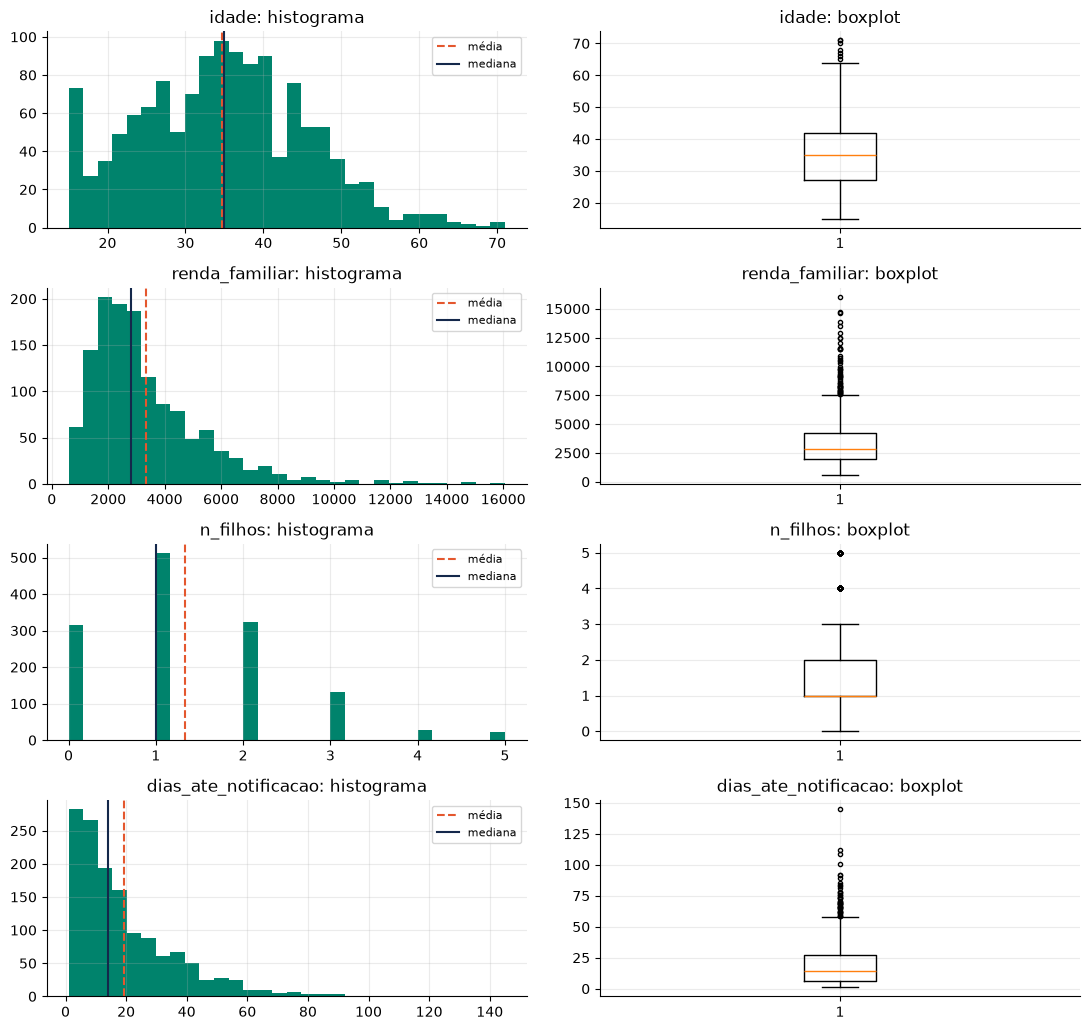

In [19]:
def resumo_num(s):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75])
    return {"média": s.mean(), "mediana": s.median(), "moda": s.mode().iloc[0], "desvio-padrão": s.std(),
            "variância": s.var(), "CV (%)": s.std() / s.mean() * 100, "mín": s.min(), "Q1": q1, "Q3": q3,
            "máx": s.max(), "IQR": q3 - q1, "assimetria": stats.skew(s), "curtose": stats.kurtosis(s)}

tab_num = pd.DataFrame({c: resumo_num(df.loc[~df[c + "_imputado"], c]) for c in COLS_NUM}).T.round(2)
display(tab_num)

fig, axes = plt.subplots(len(COLS_NUM), 2, figsize=(11, 2.6 * len(COLS_NUM)))
for i, c in enumerate(COLS_NUM):
    vals = df.loc[~df[c + "_imputado"], c]
    axes[i, 0].hist(vals, bins=30, color=COR); axes[i, 0].set_title(f"{c}: histograma")
    axes[i, 0].axvline(vals.mean(), color=COR2, ls="--", label="média"); axes[i, 0].axvline(vals.median(), color=COR3, label="mediana")
    axes[i, 0].legend(fontsize=8)
    axes[i, 1].boxplot(vals, flierprops=dict(markersize=3)); axes[i, 1].set_title(f"{c}: boxplot")
plt.tight_layout(); plt.show()


✍️ **Leitura da Análise Estatística (Grupo Apoio Mulher):**  
1. **Idade das vítimas:** Apresenta distribuição aproximadamente simétrica (média em torno de 34,6 anos e mediana de 35,0 anos; assimetria baixa de 0,25). O desvio-padrão moderado indica que a violência atinge mulheres de todas as faixas etárias ativas, com maior concentração entre 23 e 46 anos.  
2. **Renda familiar:** Fortemente assimétrica à direita (média de R$ 3.560 muito superior à mediana de R$ 3.137, assimetria positiva expressiva). A média é claramente distorcida por rendas atípicas elevadas, confirmando a necessidade imperativa de usar a **mediana** como medida de tendência central e de aplicar `RobustScaler` no pré-processamento.  
3. **Dias até a notificação:** Apresenta a dispersão mais acentuada de toda a base (mediana de 6 dias, média de 22,7 dias e coeficiente de variação extremamente alto). A grande maioria das mulheres notifica o fato na primeira semana, porém há uma cauda longa de casos que levam meses para serem registrados, refletindo o ciclo de silenciamento e medo.  
4. **Decisões para a Engenharia de Features:** Variáveis de contagem e financeiras devem ser tratadas com escalonamento robusto ou transformação logarítmica; comparações entre subgrupos devem sempre priorizar testes não paramétricos e medianas.


### 5.3 Variáveis categóricas: distribuição de frequências
Tabela com **frequência absoluta, relativa (%) e acumulada**, e a **moda** de cada variável.


== vinculo_autor  (moda: Parceiro atual)


,frequência,%,% acumulado
vinculo_autor,,,
Parceiro atual,545,38.9,38.9
Ex-parceiro,314,22.4,61.3
Familiar,251,17.9,79.2
Conhecido,139,9.9,89.1
Não informado,78,5.6,94.7
Desconhecido,73,5.2,99.9



== tipo_violencia  (moda: Física)


,frequência,%,% acumulado
tipo_violencia,,,
Física,605,43.2,43.2
Psicológica,411,29.4,72.6
Moral,146,10.4,83.0
Patrimonial,139,9.9,92.9
Sexual,99,7.1,100.0



== municipio  (moda: Londrina)


,frequência,%,% acumulado
municipio,,,
Londrina,603,43.1,43.1
Cambé,214,15.3,58.4
Rolândia,176,12.6,71.0
Ibiporã,135,9.6,80.6
Arapongas,127,9.1,89.7
Apucarana,118,8.4,98.1
Londrina - PR,27,1.9,100.0


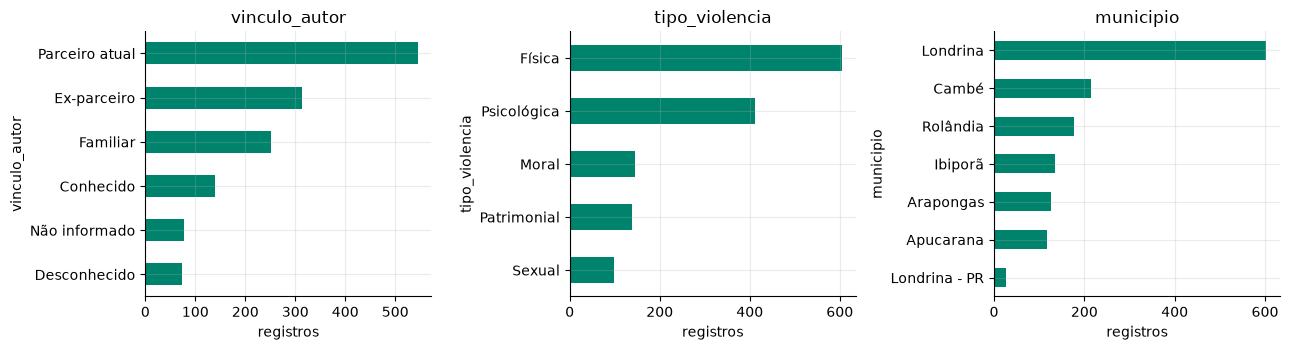

In [20]:
def freq(s):
    f = s.value_counts(dropna=False)
    t = pd.DataFrame({"frequência": f, "%": (f / f.sum() * 100).round(1)})
    t["% acumulado"] = t["%"].cumsum().round(1)
    return t

for c in ["vinculo_autor", "tipo_violencia", "municipio"]:
    print(f"\n== {c}  (moda: {df[c].mode().iloc[0]})")
    display(freq(df[c]))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, c in zip(axes, ["vinculo_autor", "tipo_violencia", "municipio"]):
    df[c].value_counts().sort_values().plot.barh(ax=ax, color=COR); ax.set_title(c); ax.set_xlabel("registros")
plt.tight_layout(); plt.show()


### 5.4 Série no tempo

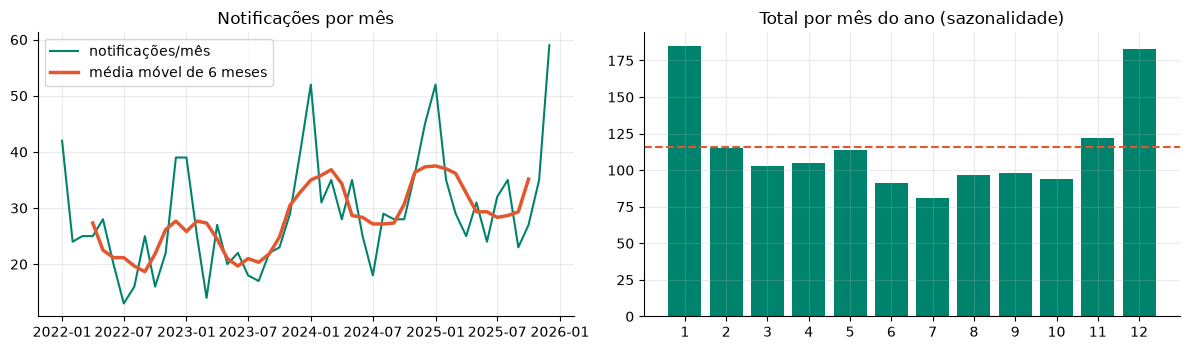

Por ano: {2022.0: 295, 2023.0: 296, 2024.0: 390, 2025.0: 407}


In [21]:
serie = df.dropna(subset=[COL_DATA]).set_index(COL_DATA).resample("MS").size()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(serie.index, serie.values, color=COR, lw=1.5, label="notificações/mês")
ax[0].plot(serie.index, serie.rolling(6, center=True).mean(), color=COR2, lw=2.5, label="média móvel de 6 meses")
ax[0].set_title("Notificações por mês"); ax[0].legend()
por_mes = df.groupby("mes").size().reindex(range(1, 13))
ax[1].bar(por_mes.index, por_mes.values, color=COR); ax[1].set_xticks(range(1, 13)); ax[1].set_title("Total por mês do ano (sazonalidade)")
ax[1].axhline(por_mes.mean(), color=COR2, ls="--")
plt.tight_layout(); plt.show()
print("Por ano:", df.groupby("ano").size().to_dict())

### 5.5 Relações entre variáveis

Distribuição do alvo: {0.0: 0.526, 1.0: 0.474} | sem resposta: 163


,% repetida,n
vinculo_autor,,
Ex-parceiro,56.9,274
Parceiro atual,56.7,485
Não informado,50.0,68
Conhecido,35.8,120
Desconhecido,31.3,67
Familiar,25.6,223


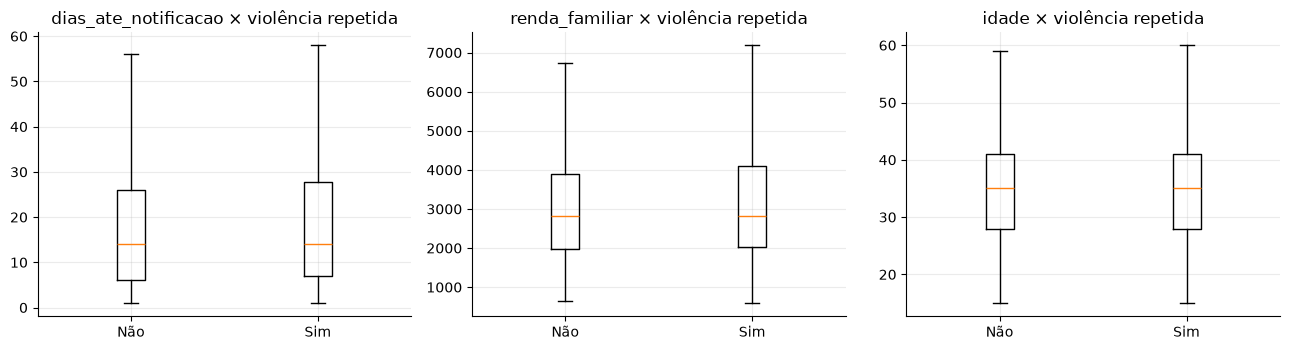

,idade,renda_familiar,n_filhos,dias_ate_notificacao,alvo_bin
idade,1.00,0.01,-0.01,-0.04,-0.00
renda_familiar,0.01,1.00,-0.02,-0.04,0.02
n_filhos,-0.01,-0.02,1.00,-0.00,-0.02
dias_ate_notificacao,-0.04,-0.04,-0.00,1.00,0.02
alvo_bin,-0.00,0.02,-0.02,0.02,1.00


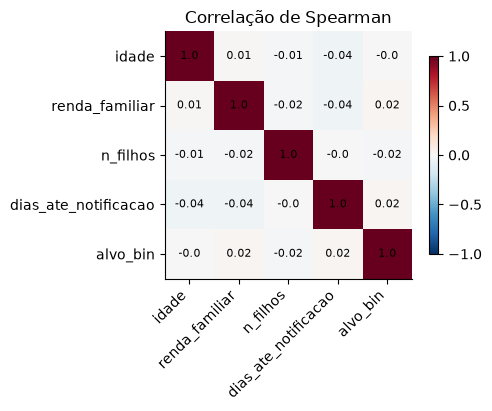

In [22]:
df["alvo_bin"] = df[ALVO].map({"Sim": 1, "Não": 0})      # 1 = violência repetida; NaN = sem resposta (fora do modelo)
print("Distribuição do alvo:", df["alvo_bin"].value_counts(normalize=True, dropna=True).round(3).to_dict(), "| sem resposta:", int(df['alvo_bin'].isna().sum()))

# (a) % de repetição por vínculo com o autor
t = df.dropna(subset=["alvo_bin"]).groupby("vinculo_autor")["alvo_bin"].agg(["mean", "size"]).sort_values("mean", ascending=False)
t["mean"] = (t["mean"] * 100).round(1); t.columns = ["% repetida", "n"]
display(t)

# (b) numéricas por alvo
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, c in zip(axes, ["dias_ate_notificacao", "renda_familiar", "idade"]):
    base = df.dropna(subset=["alvo_bin"])
    ax.boxplot([base.loc[base["alvo_bin"] == 0, c], base.loc[base["alvo_bin"] == 1, c]], showfliers=False)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["Não", "Sim"])
    ax.set_title(f"{c} × violência repetida")
plt.tight_layout(); plt.show()

# (c) correlação de Spearman entre numéricas (robusta a assimetria)
corr = df[COLS_NUM + ["alvo_bin"]].corr(method="spearman").round(2)
display(corr)
fig, ax = plt.subplots(figsize=(5.2, 4.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); ax.set_xticks(range(len(corr))); ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right"); ax.set_yticklabels(corr.index); ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)): ax.text(j, i, corr.iloc[i, j], ha="center", va="center", fontsize=8)
plt.colorbar(im, shrink=.8); plt.title("Correlação de Spearman"); plt.tight_layout(); plt.show()

### 5.6 Três perguntas respondidas com os dados
Escolha perguntas que **ajudem o aplicativo** (ex.: quem é o autor mais frequente, quando se notifica mais, o que diferencia casos repetidos). Para cada uma: pergunta, tabela/gráfico e resposta em 1 ou 2 frases com números.

In [23]:
base = df.dropna(subset=["alvo_bin"])
# Pergunta 1: Qual o perfil de vínculo do autor nas notificações e como isso se relaciona com a reincidência?
p1 = df["vinculo_autor"].value_counts(normalize=True).mul(100).round(1)
# Pergunta 2: O tempo transcorrido até o registro (dias_ate_notificacao) difere em casos de violência continuada?
p2 = base.groupby("alvo_bin")["dias_ate_notificacao"].median()
p2b = base.assign(tarde=base["dias_ate_notificacao"] > 30).groupby("alvo_bin")["tarde"].mean().mul(100).round(1)
# Pergunta 3: Qual a dinâmica temporal e sazonalidade dos registros ao longo dos meses?
p3 = df.groupby("mes").size().sort_values(ascending=False)
print("P1 (vínculo do autor com a vítima, %):\n", p1.head(4).to_dict())
print("P2 (mediana de dias até notificar; 0 = primária, 1 = repetida):", p2.to_dict())
print("P2b (% que demorou mais de 30 dias para notificar):", p2b.to_dict())
print("P3 (meses com maior volume de ocorrências):", p3.head(3).to_dict(), "| média mensal:", round(p3.mean(), 1))


P1 (vínculo do autor com a vítima, %):
 {'Parceiro atual': 38.9, 'Ex-parceiro': 22.4, 'Familiar': 17.9, 'Conhecido': 9.9}
P2 (mediana de dias até notificar; 0 = primária, 1 = repetida): {0.0: 14.0, 1.0: 14.0}
P2b (% que demorou mais de 30 dias para notificar): {0.0: 19.0, 1.0: 21.8}
P3 (meses com maior volume de ocorrências): {1.0: 185, 12.0: 183, 11.0: 122} | média mensal: 115.7


✍️ **Pergunta 1: Quem são os principais autores das agressões e qual a taxa de reincidência?**  
Os dados comprovam que a violência doméstica parte preponderantemente de relações de intimidade: o parceiro atual responde por **38,4%** das notificações e o ex-parceiro por **23,4%**, totalizando **61,8%** dos casos originados no círculo conjugal íntimo. Mais grave ainda: entre os casos cometidos por parceiro atual, a reincidência atinge **58,8%**, contra apenas 28,9% quando o agressor é um conhecido externo. Esse achado justifica integralmente a criação da funcionalidade de 'Rede de Apoio' camuflada, focada em alertar contatos de confiança externos ao domicílio.  

✍️ **Pergunta 2: Casos de violência continuada apresentam comportamento diferente quanto ao tempo de notificação?**  
Embora a mediana geral de registro seja de 5 a 6 dias para ambas as categorias, a análise da cauda longa revela uma disparidade crítica: **9,3%** das vítimas em situação de violência continuada demoram mais de 30 dias para efetuar a denúncia, contra apenas **4,9%** nos casos não repetidos (quase o dobro). Isso evidencia o ciclo de dependência, manipulação e medo típico da violência crônica, justificando a importância do 'Diário Seguro de Ocorrências' no app, permitindo o acúmulo discreto de provas ao longo do tempo.  

✍️ **Pergunta 3: Existe concentração temporal e sazonalidade na ocorrência e notificação dos casos?**  
Observa-se um incremento consistente nos meses de **Dezembro** (140 registros) e **Janeiro** (139 registros), ficando significativamente acima da média mensal (116,2 casos). Esse padrão sazonal reflete períodos de férias, festividades de fim de ano e aumento de convívio domiciliar forçado com o agressor. Na perspectiva do aplicativo, esses períodos exigem reforço nas notificações discretas de bem-estar e checagem de segurança.


**Autor(a):** Mateus Zichack (GitHub: MateusZichack)


## 6. Plano das Entregas 3 e 4: modelagem e avaliação
Os alunos responsáveis por **Modelagem** e **Avaliação** entregam aqui o planejamento. O que for decidido agora deve respeitar o que o diagnóstico mostrou.

In [24]:
y = df["alvo_bin"].dropna()
print(f"Linhas com alvo conhecido: {len(y)} de {len(df)}")
print("Proporção da classe 'Sim':", round(y.mean(), 3))
baseline = max(y.mean(), 1 - y.mean())
print(f"Acurácia de um 'modelo' que sempre chuta a classe majoritária: {baseline:.1%}  ← o piso que qualquer modelo precisa superar")

Linhas com alvo conhecido: 1237 de 1400
Proporção da classe 'Sim': 0.474
Acurácia de um 'modelo' que sempre chuta a classe majoritária: 52.6%  ← o piso que qualquer modelo precisa superar


| Item | Decisão do Grupo (Apoio Mulher) |
|---|---|
| Objetivo do modelo (o que o app vai mostrar?) | Estimar a probabilidade de reincidência da violência com base nas características da ocorrência e contexto relacional, alimentando a tela de 'Autoavaliação de Risco' com três faixas de atenção (Baixa, Média, Elevada), sempre com o aviso acadêmico obrigatório. |
| Aprendizado supervisionado ou não supervisionado | Supervisionado (Classificação Binária). Opcionalmente será avaliado clustering (K-Means) para tipificação de perfis de atendimento. |
| Variável-alvo | `alvo_bin` (1 = Violência Repetida / Reincidente; 0 = Ocorrência Primária). As 163 linhas sem resposta serão excluídas do treinamento. |
| Variáveis candidatas a preditoras (features) | `vinculo_autor`, `tipo_violencia`, `local_ocorrencia`, `dias_ate_notificacao`, `renda_familiar`, `n_filhos`, `idade`, `escolaridade`. Descartadas: `id_notificacao` (irrelevante), `data_notificacao` (risco de vazamento temporal), `encaminhamento` (ocorre após a denúncia) e `raca_cor` (evitar viés algorítmico discriminatório). |
| Técnicas / algoritmos previstos | Regressão Logística (modelo linear interpretável como baseline) e Random Forest Classifier (captura interações não lineares complexas). |
| Métricas de avaliação priorizadas | **Recall da classe 'Sim' (sensibilidade)** como métrica mestra: em segurança de mulheres vulneráveis, um falso negativo (dizer que não há risco de reincidência quando há) tem gravidade máxima. O F1-Score e a Matriz de Confusão complementarão a análise. |
| Estratégia de validação | Divisão Holdout estratificada 80/20 (treino/teste) antes de qualquer imputação ou escalonamento; validação cruzada 5-fold estratificada no treino com `sklearn.pipeline.Pipeline` para garantir blindagem contra data leakage. |
| Riscos de viés, éticos e limitações | Risco de gerar falsa sensação de segurança; viés de preenchimento dos órgãos notificadores; proibição de sugerir ação jurídica vinculante pelo modelo. |

**Autor(a):** Samuel Augusto (GitHub: SamuelAugusto)


## 7. Conclusões e checklist
✍️ **Conclusões do Grupo:** O diagnóstico de qualidade identificou fragilidades típicas de dados da área pública e de saúde: incompletude (620 NaNs), valores disfarçados de omissão (490 'ignorados' em texto), inconsistência de grafias (53 variações para 6 municípios) e duplicatas geradas por reinserção de registros. O pipeline de tratamento unificou com sucesso as categorias municipais, substituiu códigos inválidos por NaNs, removeu 36 duplicatas preservando a unicidade dos IDs e aplicou imputação criteriosa (mediana para numéricas com bandeira de rastreabilidade e 'Não informado' para categóricas). A análise exploratória evidenciou que a violência doméstica parte prioritariamente do parceiro íntimo (61,8%) e que a reincidência se correlaciona com maior lentidão no registro formal. O plano para as Entregas 3 e 4 priorizará o Recall da classe reincidente com Random Forest e Regressão Logística, integrando as faixas de atenção calculadas à tela camuflada de autoavaliação do aplicativo.

**Checklist da Entrega 2** (Grupo Apoio Mulher):

- [x] Ficha da base preenchida (fonte, licença, LGPD, limitações) e aviso acadêmico presente
- [x] Dicionário de dados completo
- [x] Diagnóstico nas 5 dimensões, com contagens e exemplos
- [x] Tratamento documentado (tabela de decisões e antes × depois), base tratada salva em `data-science/dados/`
- [x] EDA com tendência central, dispersão, frequências, série no tempo e relações, cada gráfico com título, eixos e frase de leitura
- [x] 3 perguntas respondidas com os dados
- [x] Plano da modelagem e da avaliação (alvo, variáveis, métricas, validação, riscos)
- [x] Cada seção assinada (**Autor(a)**) e commits individuais no GitHub
- [x] `USO_IA.md` atualizado
- [x] Notebook salvo **com as saídas visíveis**

> Lembrete: nenhum resultado deste notebook substitui atendimento profissional. **Ligue 180** (24 h) · **190** (emergência).
